# 02 · Preprocessing Data
## Estimasi Harga Rumah California dengan MLP Regresi

Notebook ini menerapkan keputusan preprocessing dari `01_eda.ipynb` menjadi **pipeline yang bisa dipakai ulang**
(`HousingPreprocessor`). Pipeline ini identik dengan `backend/preprocess.py`, yaitu yang dipakai `train.py` dan `app.py`,
dan hal itu diverifikasi di bagian 6.

**Tugas model:** regresi, memprediksi `median_house_value` (USD). Data berupa **tabular** (bukan citra atau teks).

### Pemetaan ke ketentuan preprocessing

| Ketentuan | Isi | Bagian di notebook |
|---|---|---|
| a | Pembersihan data (duplikat, data rusak, label salah) | 1 |
| e | Pembagian data train/validation/test, proporsi, dan pencegahan kebocoran data | 2 |
| d | Penanganan missing value, outlier, dan ketidakseimbangan kelas | 3 |
| b | Normalisasi/standardisasi (transformasi, encoding, scaling) | 4 |
| c | Augmentasi data | 5 |
| – | Pipeline akhir, verifikasi terhadap backend, dan penyimpanan hasil | 6 |

> **Mengapa urutannya bukan a-b-c-d-e?** Imputasi (d) dan scaling (b) menghitung statistik dari data. Supaya tidak terjadi
> *data leakage*, data harus **dibagi lebih dulu (e)**, lalu statistik dihitung dari **train saja**. Karena itu bagian e
> dikerjakan sebelum d dan b, sementara tiap bagian tetap diberi label hurufnya.

In [1]:
import sys, os, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/california-house-price-mlp"):
        subprocess.run(["git", "clone", "https://github.com/lukito789/california-house-price-mlp.git"],
                       cwd="/content", check=True)
    os.chdir("/content/california-house-price-mlp/notebooks")

## 0. Setup

In [2]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Notebook ini bisa dijalankan dari folder notebooks/ maupun dari folder utama proyek
ROOT = Path.cwd()
if not (ROOT / "data" / "housing.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "housing.csv"
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# ---- Konfigurasi (sama dengan backend/preprocess.py dan backend/train.py) ----
TARGET = "median_house_value"
CAT_FEATURE = "ocean_proximity"
NUM_FEATURES = ["longitude", "latitude", "housing_median_age", "total_rooms",
                "total_bedrooms", "population", "households", "median_income"]
LOG_COLS = ["total_rooms", "total_bedrooms", "population", "households"]
CATEGORIES = ["<1H OCEAN", "INLAND", "ISLAND", "NEAR BAY", "NEAR OCEAN"]
TARGET_SCALE = 100_000.0     # target dilatih dalam satuan $100 ribu
SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # sisanya 15% untuk test

# backend/preprocess.py hanya dipakai untuk verifikasi di bagian 6
sys.path.insert(0, str(ROOT / "backend"))
import preprocess as backend_prep

print("Dataset :", DATA_PATH)
print("Output  :", OUT_DIR)

Dataset : /content/california-house-price-mlp/data/housing.csv
Output  : /content/california-house-price-mlp/data/processed


## 0.1 Memuat data mentah

In [ ]:
raw = pd.read_csv(DATA_PATH)
print(f"Baris: {raw.shape[0]:,} | Kolom: {raw.shape[1]}")
display(raw.head())

Baris: 20,640 | Kolom: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Pembersihan Data (ketentuan a)

**Alasan:** model hanya bisa belajar dari data yang benar. Baris duplikat membuat sebagian pola terhitung dua kali dan,
lebih berbahaya, bisa jatuh ke train *dan* test sekaligus sehingga skor evaluasi tampak lebih bagus dari kenyataan. Nilai yang
mustahil atau label yang salah akan diperlakukan model sebagai sinyal yang sah. Tiga hal diperiksa: **duplikat**,
**data rusak**, dan **label salah**.

### 1.1 Duplikat

In [ ]:
n_dup_all = int(raw.duplicated().sum())
n_dup_feat = int(raw.duplicated(subset=NUM_FEATURES + [CAT_FEATURE]).sum())
print(f"Baris duplikat penuh (semua kolom)       : {n_dup_all}")
print(f"Baris duplikat pada fitur (tanpa target) : {n_dup_feat}")

Baris duplikat penuh (semua kolom)       : 0
Baris duplikat pada fitur (tanpa target) : 0


Tidak ada duplikat, jadi tidak ada baris yang dihapus. Pemeriksaan ini tetap dijalankan, bukan dilewati, karena hasilnya
menentukan apakah risiko duplikat lintas split perlu ditangani (diperiksa ulang di bagian 2).

### 1.2 Data rusak (tipe salah, di luar rentang, tidak logis)

Tiga jenis pemeriksaan: (1) semua kolom numerik benar-benar numerik, (2) nilai berada dalam rentang yang masuk akal untuk
California, (3) hubungan logis antarkolom.

In [ ]:
# (1) Tipe data: apakah ada sel teks yang gagal dibaca sebagai angka?
bad_type = {c: int(pd.to_numeric(raw[c], errors="coerce").isna().sum() - raw[c].isna().sum())
            for c in NUM_FEATURES + [TARGET]}
print("Sel non-numerik pada kolom numerik:", {k: v for k, v in bad_type.items() if v} or "tidak ada")

# (2) Rentang yang masuk akal (batas wilayah California: lat 32.5-42.0, lon -124.5 sampai -114.0)
valid_range = {
    "longitude": (-124.5, -114.0),
    "latitude": (32.5, 42.0),
    "housing_median_age": (0, 100),
    "total_rooms": (1, np.inf),
    "total_bedrooms": (1, np.inf),
    "population": (1, np.inf),
    "households": (1, np.inf),
    "median_income": (0, np.inf),
    TARGET: (0, np.inf),
}
rows = []
for col, (lo, hi) in valid_range.items():
    s = raw[col].dropna()
    n_bad = int(((s < lo) | (s > hi) | ((lo == 0) & (s <= 0))).sum())
    rows.append({"kolom": col, "min": s.min(), "maks": s.max(), "rentang_valid": f"{lo} .. {hi}", "pelanggaran": n_bad})
display(pd.DataFrame(rows).set_index("kolom"))

# (3) Konsistensi logis antarkolom
logic = {
    "total_bedrooms > total_rooms (kamar tidur melebihi total kamar)": int((raw["total_bedrooms"] > raw["total_rooms"]).sum()),
    "households > population (rumah tangga melebihi penduduk)": int((raw["households"] > raw["population"]).sum()),
}
for k, v in logic.items():
    print(f"{k:<70}: {v}")
display(raw[raw["households"] > raw["population"]])

Sel non-numerik pada kolom numerik: tidak ada


,min,maks,rentang_valid,pelanggaran
kolom,,,,
longitude,-124.3500,-114.3100,-124.5 .. -114.0,0
latitude,32.5400,41.9500,32.5 .. 42.0,0
housing_median_age,1.0000,52.0000,0 .. 100,0
total_rooms,2.0000,39320.0000,1 .. inf,0
total_bedrooms,1.0000,6445.0000,1 .. inf,0
population,3.0000,35682.0000,1 .. inf,0
households,1.0000,6082.0000,1 .. inf,0
median_income,0.4999,15.0001,0 .. inf,0
median_house_value,14999.0000,500001.0000,0 .. inf,0


total_bedrooms > total_rooms (kamar tidur melebihi total kamar)       : 0
households > population (rumah tangga melebihi penduduk)              : 3


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
5342,-118.44,34.04,16.0,18.0,6.0,3.0,4.0,0.5360,350000.0,<1H OCEAN
11849,-121.00,39.75,8.0,1116.0,214.0,27.0,39.0,2.5893,83000.0,INLAND
19522,-121.00,37.65,17.0,484.0,202.0,198.0,204.0,0.6825,187500.0,INLAND


**Hasil:** tidak ada sel non-numerik dan tidak ada nilai di luar rentang. Satu-satunya yang janggal adalah **3 baris** dengan
`households > population`. Secara logika tiap rumah tangga minimal berpenduduk satu orang, jadi baris ini mencurigakan.

**Keputusan: dipertahankan.** Jumlahnya 3 dari 20.640 baris (0,015%), pengaruhnya dapat diabaikan, dan model di `backend/artifacts/`
dilatih dengan baris ini. Menghapusnya berarti melatih ulang model dan mengubah hasil yang sudah dilaporkan. Baris ini dicatat
sebagai peringatan kualitas data.

### 1.3 Label salah

Pada proyek regresi ini ada dua "label": **target** (`median_house_value`) dan satu **fitur kategorikal** (`ocean_proximity`).
Untuk target diperiksa nilai kosong, nilai tidak positif, dan nilai yang terpotong. Untuk kategori diperiksa apakah ada
penulisan yang tidak dikenal (salah ketik, spasi, huruf besar-kecil).

In [ ]:
# Kategori: apakah semua nilai termasuk 5 kategori yang dikenal?
cat_counts = raw[CAT_FEATURE].value_counts(dropna=False)
unknown = sorted(set(raw[CAT_FEATURE].dropna().unique()) - set(CATEGORIES))
print("Kategori ocean_proximity:")
display(cat_counts.to_frame("jumlah"))
print("Kategori tidak dikenal :", unknown or "tidak ada")
print("Ada spasi di awal/akhir:", int((raw[CAT_FEATURE].dropna() != raw[CAT_FEATURE].dropna().str.strip()).sum()))

# Target
y_raw = raw[TARGET]
cap = y_raw.max()
print(f"\nTarget kosong     : {int(y_raw.isna().sum())}")
print(f"Target <= 0       : {int((y_raw <= 0).sum())}")
print(f"Target terpotong  : {int((y_raw == cap).sum()):,} baris bernilai tepat ${cap:,.0f} "
      f"({(y_raw == cap).mean() * 100:.2f}%)")

Kategori ocean_proximity:


,jumlah
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


Kategori tidak dikenal : tidak ada
Ada spasi di awal/akhir: 0

Target kosong     : 0
Target <= 0       : 0
Target terpotong  : 965 baris bernilai tepat $500,001 (4.68%)


Semua label kategori valid. Target tidak kosong dan tidak ada yang `<= 0`. Satu-satunya masalah label adalah **965 baris
yang terpotong di \$500.001** (batas atas saat pengumpulan data). Ini bukan kesalahan input yang bisa diperbaiki, karena harga
sebenarnya tidak diketahui. Baris tersebut **dipertahankan** dan dicatat sebagai keterbatasan, bukan dibuang atau diubah.

### 1.4 Eksekusi pembersihan

Aturan yang diterapkan sama dengan `train.py`: buang baris yang target atau `ocean_proximity`-nya kosong. Nilai kosong pada
fitur numerik **tidak** dibuang di sini; ditangani lewat imputasi di bagian 3.

In [ ]:
df = raw.drop_duplicates()
df = df.dropna(subset=[TARGET, CAT_FEATURE])

summary = pd.DataFrame({
    "langkah": ["Data mentah", "Hapus duplikat", "Hapus target/kategori kosong"],
    "jumlah_baris": [len(raw), len(raw.drop_duplicates()), len(df)],
})
summary["baris_dibuang"] = summary["jumlah_baris"].shift(1, fill_value=len(raw)) - summary["jumlah_baris"]
display(summary)
print(f"Data bersih: {len(df):,} baris")

,langkah,jumlah_baris,baris_dibuang
0,Data mentah,20640,0
1,Hapus duplikat,20640,0
2,Hapus target/kategori kosong,20640,0


Data bersih: 20,640 baris


## 2. Pembagian Data (ketentuan e)

**Alasan dan proporsi:** data dibagi tiga dengan peran berbeda.

| Subset | Proporsi | Peran |
|---|---|---|
| Training | **70%** | Melatih bobot MLP, juga menjadi satu-satunya sumber statistik preprocessing |
| Validation | **15%** | Memantau *overfitting*, dipakai oleh `EarlyStopping` dan `ReduceLROnPlateau`, serta memilih hyperparameter |
| Testing | **15%** | Evaluasi akhir yang jujur, hanya disentuh **sekali** setelah model selesai |

Dataset berukuran sedang (20.640 baris), sehingga 15% (sekitar 3.100 baris) cukup besar agar metrik val/test stabil, sementara
70% (sekitar 14.400 baris) cukup untuk melatih MLP kecil. Pembagian acak dengan `seed = 42`, sama persis dengan `train.py`.
Stratifikasi tidak dipakai karena targetnya kontinu. Sebagai gantinya, kemiripan distribusi antar-subset diperiksa di bawah.

In [ ]:
shuffled = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

n = len(shuffled)
n_tr, n_va = int(n * TRAIN_FRAC), int(n * VAL_FRAC)
train_df = shuffled.iloc[:n_tr].copy()
val_df = shuffled.iloc[n_tr:n_tr + n_va].copy()
test_df = shuffled.iloc[n_tr + n_va:].copy()

split_tbl = pd.DataFrame({
    "jumlah_baris": [len(train_df), len(val_df), len(test_df)],
    "proporsi_%": [len(d) / n * 100 for d in (train_df, val_df, test_df)],
}, index=["train", "validation", "test"]).round(2)
display(split_tbl)
assert len(train_df) + len(val_df) + len(test_df) == n

,jumlah_baris,proporsi_%
train,14447,70.0
validation,3096,15.0
test,3097,15.0


### 2.1 Apakah ketiga subset mirip distribusinya?

,train,validation,test
count,14447.0,3096.0,3097.0
mean,207184.0,204170.0,208012.0
std,115293.0,114436.0,116818.0
min,14999.0,14999.0,14999.0
25%,120000.0,117975.0,120800.0
50%,180400.0,177000.0,180900.0
75%,265900.0,259925.0,264200.0
max,500001.0,500001.0,500001.0


,train,validation,test
ocean_proximity (%),,,
<1H OCEAN,44.04,43.86,45.72
INLAND,31.53,32.88,31.58
NEAR OCEAN,13.23,12.44,11.66
NEAR BAY,11.18,10.79,11.01
ISLAND,0.02,0.03,0.03


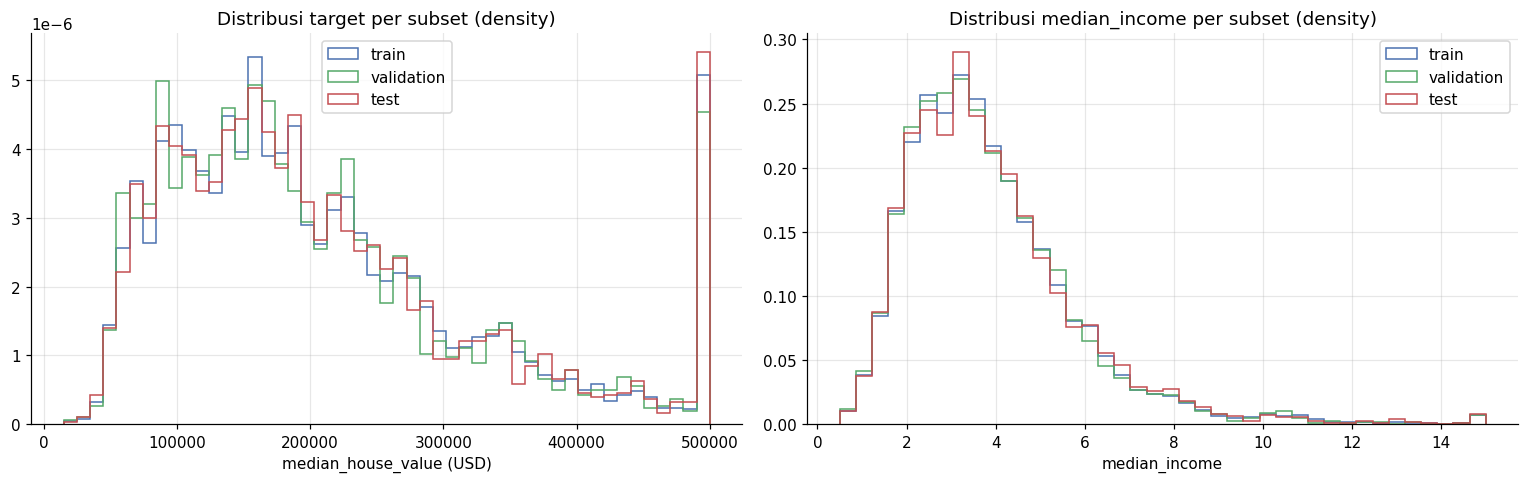

In [ ]:
splits = {"train": train_df, "validation": val_df, "test": test_df}

# Target
display(pd.DataFrame({k: v[TARGET].describe() for k, v in splits.items()}).round(0))

# Kategori
cat_prop = pd.DataFrame({k: v[CAT_FEATURE].value_counts(normalize=True) for k, v in splits.items()}).fillna(0) * 100
display(cat_prop.round(2).rename_axis("ocean_proximity (%)"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
colors = {"train": "#4C72B0", "validation": "#55A868", "test": "#C44E52"}
bins = np.linspace(raw[TARGET].min(), raw[TARGET].max(), 50)
for k, v in splits.items():
    ax[0].hist(v[TARGET], bins=bins, density=True, histtype="step", lw=1.8, color=colors[k], label=k)
ax[0].set(title="Distribusi target per subset (density)", xlabel="median_house_value (USD)")
ax[0].legend()

for k, v in splits.items():
    ax[1].hist(v["median_income"], bins=40, density=True, histtype="step", lw=1.8, color=colors[k], label=k)
ax[1].set(title="Distribusi median_income per subset (density)", xlabel="median_income")
ax[1].legend()
plt.tight_layout()
save_fig("09_distribusi_antar_split")
plt.show()

Kurva ketiga subset hampir berimpit dan proporsi kategori mirip, jadi pembagian acak sudah representatif. Hanya kategori
`ISLAND` yang terdistribusi tidak merata, karena totalnya cuma 5 baris (3 di train, 1 di validation, 1 di test).

### 2.2 Pencegahan kebocoran data (*data leakage*)

Kebocoran terjadi ketika informasi dari data validation/test ikut memengaruhi training. Langkah pencegahan yang dipakai:

| # | Risiko | Pencegahan | Pembuktian |
|---|---|---|---|
| 1 | Statistik (median, mean, std) dihitung dari seluruh data | Split dilakukan **sebelum** imputasi dan scaling; semua statistik di-*fit* pada **train saja** lalu dipakai ulang untuk val/test | Bagian 3 dan 4 |
| 2 | Baris yang sama muncul di dua subset | Data diacak lalu dipotong berurutan (tanpa tumpang tindih) dan tidak ada duplikat | Pemeriksaan di bawah |
| 3 | Test dipakai untuk memilih model | Early stopping dan penjadwalan learning rate memakai **validation**; test dipakai sekali di akhir | `train.py` |
| 4 | Transformasi target memakai statistik data | Target hanya dibagi konstanta tetap (100.000), tanpa statistik dari data | Bagian 4.4 |
| 5 | Preprocessing training dan inference berbeda | Parameter disimpan (`prep.json`) dan dipakai ulang oleh API | Bagian 6 |

In [ ]:
# Bukti 2: tidak ada baris yang sama di dua subset
idx_sets = {k: set(map(tuple, v[NUM_FEATURES + [TARGET]].fillna(-999).to_numpy())) for k, v in splits.items()}
pairs = [("train", "validation"), ("train", "test"), ("validation", "test")]
for a, b in pairs:
    print(f"Baris sama di {a:<10} dan {b:<10}: {len(idx_sets[a] & idx_sets[b])}")

# Bukti 1: seberapa besar bedanya bila median dihitung dari SEMUA data (cara yang salah)?
leak = pd.DataFrame({
    "median_train_saja (benar)": train_df[NUM_FEATURES].median(),
    "median_seluruh_data (bocor)": df[NUM_FEATURES].median(),
})
leak["selisih"] = leak.iloc[:, 1] - leak.iloc[:, 0]
display(leak.round(4))

Baris sama di train      dan validation: 0
Baris sama di train      dan test      : 0
Baris sama di validation dan test      : 0


,median_train_saja (benar),median_seluruh_data (bocor),selisih
longitude,-118.4900,-118.4900,0.0000
latitude,34.2500,34.2600,0.0100
housing_median_age,29.0000,29.0000,0.0000
total_rooms,2116.0000,2127.0000,11.0000
total_bedrooms,433.0000,435.0000,2.0000
population,1162.0000,1166.0000,4.0000
households,408.0000,409.0000,1.0000
median_income,3.5391,3.5348,-0.0043


Tidak ada baris yang tumpang tindih. Tabel kedua menunjukkan bahwa menghitung median dari seluruh data memberi angka yang
sedikit berbeda (contoh: `total_bedrooms` 435 vs 433). Selisihnya kecil di dataset ini, tetapi prinsipnya tetap dijaga karena
pada data lain atau saat deployment, kebocoran sekecil apa pun membuat evaluasi terlalu optimis.

**Temuan yang perlu dicatat:** dengan `seed = 42`, seluruh 207 baris `total_bedrooms` yang kosong kebetulan jatuh ke **train**
(validation dan test tidak memiliki nilai kosong). Konsekuensinya, jalur imputasi tidak pernah diuji oleh val/test. Ini bukan
bug, hanya akibat pembagian acak, tetapi sebaiknya diketahui saat membaca hasil evaluasi. Detailnya ada di bagian 3.1.

## 3. Missing Value, Outlier, dan Ketidakseimbangan Kelas (ketentuan d)

### 3.1 Missing value

**Alasan dan metode:** hanya `total_bedrooms` yang memiliki nilai kosong. MLP tidak dapat menerima `NaN` (gradien menjadi `NaN`),
sehingga nilainya harus diisi. Di EDA terbukti bahwa kekosongan tampak acak (rata-rata fitur lain dan harga sama dengan baris
lengkap), maka imputasi sederhana sudah aman. Dipilih **median** karena kuat terhadap distribusi yang sangat miring (rata-rata
akan tertarik oleh blok besar), dan dihitung dari **train saja**. Imputasi diterapkan ke semua fitur numerik supaya saat
inference, input dari pengguna yang kosong juga tetap bisa diproses.

In [ ]:
miss = pd.DataFrame({k: v[NUM_FEATURES].isna().sum() for k, v in splits.items()})
miss = miss[miss.sum(axis=1) > 0]
print("Nilai kosong per subset (sebelum imputasi):")
display(miss)

# Statistik imputasi: dari TRAIN saja
fill_values = {c: float(train_df[c].median()) for c in NUM_FEATURES}
display(pd.Series(fill_values, name="median_train").to_frame().T.round(4))

# Terapkan ke ketiga subset
def impute(d, fill):
    d = d.copy()
    for c, v in fill.items():
        d[c] = d[c].fillna(v)
    return d

train_i, val_i, test_i = (impute(d, fill_values) for d in (train_df, val_df, test_df))
print("Sisa nilai kosong setelah imputasi:", int(sum(d[NUM_FEATURES].isna().sum().sum() for d in (train_i, val_i, test_i))))

Nilai kosong per subset (sebelum imputasi):


,train,validation,test
total_bedrooms,207,0,0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
median_train,-118.49,34.25,29.0,2116.0,433.0,1162.0,408.0,3.5391


Sisa nilai kosong setelah imputasi: 0


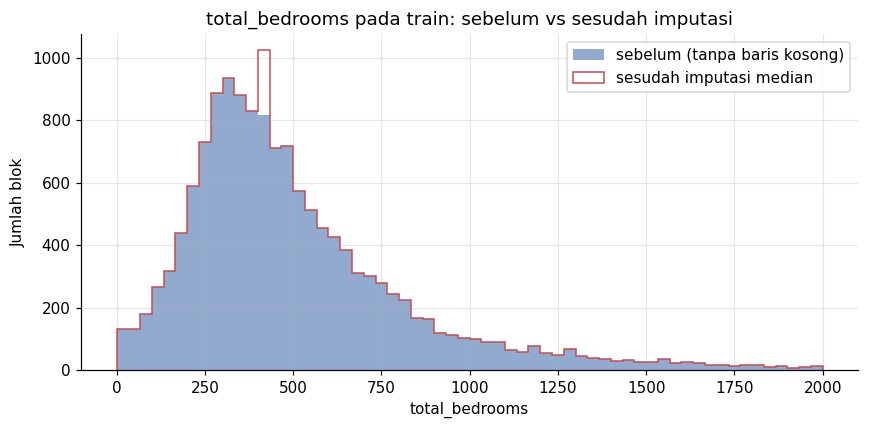

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
before = train_df["total_bedrooms"].dropna()
ax.hist(before, bins=60, range=(0, 2000), color="#4C72B0", alpha=0.6, label="sebelum (tanpa baris kosong)")
ax.hist(train_i["total_bedrooms"], bins=60, range=(0, 2000), histtype="step", lw=1.8, color="#C44E52", label="sesudah imputasi median")
ax.set(title="total_bedrooms pada train: sebelum vs sesudah imputasi", xlabel="total_bedrooms", ylabel="Jumlah blok")
ax.legend()
plt.tight_layout()
save_fig("10_imputasi_total_bedrooms")
plt.show()

Setelah imputasi tidak ada nilai kosong tersisa. Histogram memperlihatkan bentuk distribusi hampir tidak berubah; yang
bertambah hanya satu batang di sekitar median (207 baris, atau 1,4% dari train). Itu efek wajar imputasi median dan dampaknya kecil.

### 3.2 Outlier

**Alasan dan keputusan:** outlier dideteksi dengan aturan IQR (batas 1,5 kali IQR), dengan batas yang **dihitung dari train**.
Dari EDA, keempat fitur hitungan memiliki sekitar 6% outlier. Blok sensus yang sangat besar memang ada di dunia nyata
(misalnya kawasan padat), jadi nilai itu **valid, bukan salah ukur**. Menghapusnya membuat model buta terhadap blok besar, yang
tetap akan muncul saat inference. Strategi yang dipakai: **tidak menghapus, tetapi meredam dengan `log1p`** (bagian 4.1).

In [ ]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in NUM_FEATURES:
    lo, hi = iqr_bounds(train_i[c])               # batas dari TRAIN
    row = {"fitur": c}
    for k, d in {"train": train_i, "validation": val_i, "test": test_i}.items():
        row[f"outlier_{k}_%"] = ((d[c] < lo) | (d[c] > hi)).mean() * 100
    rows.append(row)
display(pd.DataFrame(rows).set_index("fitur").round(2))

,outlier_train_%,outlier_validation_%,outlier_test_%
fitur,,,
longitude,0.00,0.00,0.00
latitude,0.00,0.00,0.00
housing_median_age,0.00,0.00,0.00
total_rooms,6.15,6.49,6.65
total_bedrooms,6.26,6.62,6.59
population,5.94,5.81,5.84
households,5.90,6.27,5.88
median_income,3.25,3.20,3.49


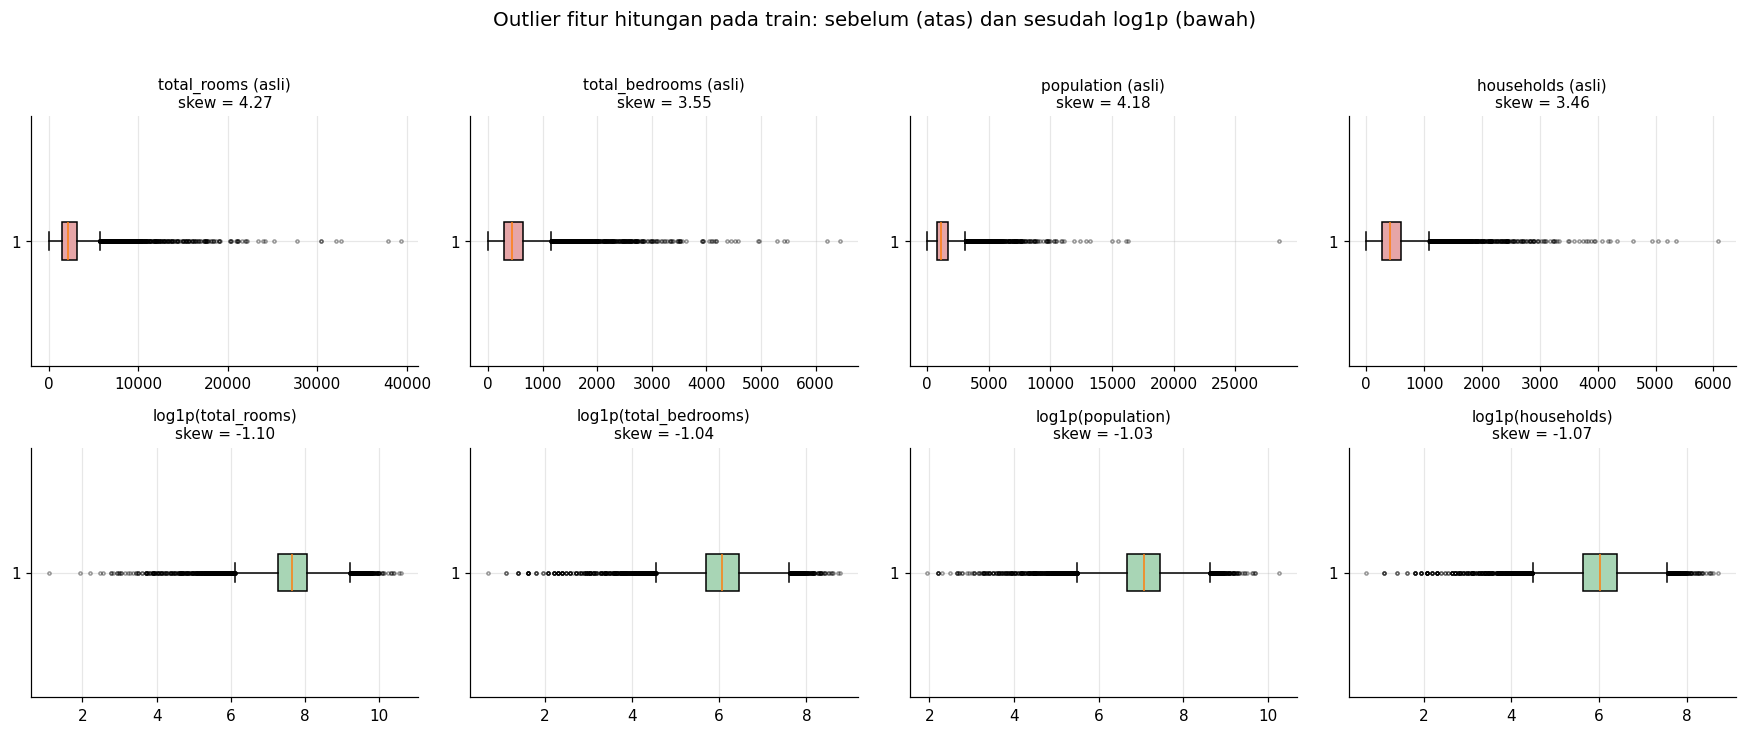

,skew_asli,skew_log1p,outlier_asli_%,outlier_log1p_%
total_rooms,4.27,-1.10,6.15,4.64
total_bedrooms,3.55,-1.04,6.26,4.13
population,4.18,-1.03,5.94,4.01
households,3.46,-1.07,5.90,4.25


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, c in enumerate(LOG_COLS):
    axes[0, i].boxplot(train_i[c], vert=False, patch_artist=True, boxprops={"facecolor": "#e6a5a7"},
                       flierprops={"markersize": 2, "alpha": 0.4})
    axes[0, i].set_title(f"{c} (asli)\nskew = {train_i[c].skew():.2f}", fontsize=10)
    lg = np.log1p(train_i[c])
    axes[1, i].boxplot(lg, vert=False, patch_artist=True, boxprops={"facecolor": "#a8d5b5"},
                       flierprops={"markersize": 2, "alpha": 0.4})
    axes[1, i].set_title(f"log1p({c})\nskew = {lg.skew():.2f}", fontsize=10)
fig.suptitle("Outlier fitur hitungan pada train: sebelum (atas) dan sesudah log1p (bawah)", fontsize=13, y=1.02)
plt.tight_layout()
save_fig("11_outlier_sebelum_sesudah_log1p")
plt.show()

out_tbl = pd.DataFrame({
    "skew_asli": [train_i[c].skew() for c in LOG_COLS],
    "skew_log1p": [np.log1p(train_i[c]).skew() for c in LOG_COLS],
    "outlier_asli_%": [((train_i[c] < iqr_bounds(train_i[c])[0]) | (train_i[c] > iqr_bounds(train_i[c])[1])).mean() * 100 for c in LOG_COLS],
    "outlier_log1p_%": [((np.log1p(train_i[c]) < iqr_bounds(np.log1p(train_i[c]))[0]) |
                         (np.log1p(train_i[c]) > iqr_bounds(np.log1p(train_i[c]))[1])).mean() * 100 for c in LOG_COLS],
}, index=LOG_COLS)
display(out_tbl.round(2))

`log1p` menurunkan skewness pada train dari 3,5 sampai 4,3 menjadi sekitar −1, dan persentase outlier ikut turun (sekitar 6% menjadi 4 sampai 4,6%). Outlier yang
tersisa adalah ekor kiri (blok sangat kecil), yang wajar. Fitur lain (`longitude`, `latitude`, `housing_median_age`,
`median_income`) tidak ditransformasi. Dua yang menumpuk di batas atas (`housing_median_age` = 52 dan `median_income` = 15)
adalah *capping* dari sumber data. Itu dibiarkan dan dicatat sebagai keterbatasan, sama seperti target yang terpotong.

**Fitur rasio (opsional, tidak masuk pipeline akhir).** EDA mengusulkan `rooms_per_household`, `bedrooms_per_room`, dan
`population_per_household` sebagai eksperimen, dengan nilai ekstrem yang perlu dibatasi (*clip*). Cuplikan di bawah memperlihatkan
cara melakukannya: batas persentil ke-1 dan ke-99 diambil dari **train**.

In [ ]:
def ratio_features(d):
    return pd.DataFrame({
        "rooms_per_household": d["total_rooms"] / d["households"],
        "bedrooms_per_room": d["total_bedrooms"] / d["total_rooms"],
        "population_per_household": d["population"] / d["households"],
    })

r_train = ratio_features(train_i)
clip_lo, clip_hi = r_train.quantile(0.01), r_train.quantile(0.99)       # batas dari TRAIN
r_clipped = r_train.clip(clip_lo, clip_hi, axis=1)

display(pd.DataFrame({
    "maks_sebelum_clip": r_train.max(), "maks_sesudah_clip": r_clipped.max(),
    "skew_sebelum": r_train.skew(), "skew_sesudah": r_clipped.skew(),
}).round(2))

,maks_sebelum_clip,maks_sesudah_clip,skew_sebelum,skew_sesudah
rooms_per_household,132.53,10.39,18.31,0.83
bedrooms_per_room,2.81,0.42,7.29,1.17
population_per_household,1243.33,5.45,92.59,0.88


Clipping menjinakkan nilai ekstrem (misalnya `population_per_household` yang semula maksimum 1.243 menjadi sekitar 5,5). **Fitur rasio sengaja
tidak dimasukkan ke pipeline akhir**, karena model yang tersimpan di `backend/artifacts/` dilatih tanpa fitur ini dan
`app.py` menerima 8 fitur mentah. Menambahkannya berarti melatih ulang model dan mengubah API. Kode di atas disimpan sebagai
bahan eksperimen berikutnya.

### 3.3 Ketidakseimbangan kelas

**Alasan dan keputusan:** proyek ini **regresi**, targetnya angka kontinu dan **tidak memiliki kelas**. Karena itu
ketidakseimbangan kelas dalam arti klasik tidak berlaku. Teknik penyeimbang seperti SMOTE, *oversampling*, atau
*undersampling* tidak dipakai, sebab teknik itu dibuat untuk label diskret dan akan menciptakan "rumah sintetis" tanpa dasar.

Ada tiga hal yang mirip ketidakseimbangan dan tetap diperiksa:

In [ ]:
# (1) Kategori ocean_proximity per subset (jumlah baris)
cat_cnt = pd.DataFrame({k: v[CAT_FEATURE].value_counts() for k, v in splits.items()}).fillna(0).astype(int)
cat_cnt["total"] = cat_cnt.sum(axis=1)
display(cat_cnt.rename_axis("ocean_proximity"))

# (2) Porsi target yang terpotong ($500.001) per subset
cap_share = pd.Series({k: (v[TARGET] == cap).mean() * 100 for k, v in splits.items()}, name="% target terpotong")
display(cap_share.round(2).to_frame().T)

# (3) Sebaran target per rentang harga (apakah ada rentang yang sangat jarang?)
bins_y = [0, 100_000, 200_000, 300_000, 400_000, 500_000, np.inf]
labels_y = ["<100k", "100-200k", "200-300k", "300-400k", "400-500k", "500k+ (cap)"]
y_bin = pd.DataFrame({k: pd.cut(v[TARGET], bins_y, labels=labels_y, right=False).value_counts(normalize=True).sort_index() * 100
                      for k, v in splits.items()})
display(y_bin.round(1).rename_axis("rentang harga (%)"))

,train,validation,test,total
ocean_proximity,,,,
<1H OCEAN,6362,1358,1416,9136
INLAND,4555,1018,978,6551
NEAR OCEAN,1912,385,361,2658
NEAR BAY,1615,334,341,2290
ISLAND,3,1,1,5


,train,validation,test
% target terpotong,4.74,4.1,4.94


,train,validation,test
rentang harga (%),,,
<100k,17.2,18.2,17.5
100-200k,40.3,39.8,40.1
200-300k,23.7,24.0,23.5
300-400k,10.3,9.9,9.9
400-500k,3.7,4.1,3.9
500k+ (cap),4.9,4.2,5.1


- **Kategori:** `ISLAND` sangat langka (5 baris), tetapi bukan label yang diprediksi, melainkan fitur. Dipertahankan agar seluruh
  kategori dataset tetap terwakili. Model hampir tidak bisa mempelajarinya, dan itu dicatat sebagai keterbatasan.
- **Target terpotong:** porsinya mirip di ketiga subset (sekitar 4 sampai 5%), jadi tidak ada subset yang bias.
- **Rentang harga:** semua rentang terwakili di ketiga subset dengan proporsi yang mirip. Rentang `500k+` adalah harga yang terpotong.

**Keputusan:** tanpa resampling, tanpa pembobotan sampel. Kesimpulan ini diperkuat oleh pemeriksaan kemiripan distribusi
pada bagian 2.1.

## 4. Normalisasi dan Standardisasi (ketentuan b)

Data proyek ini **tabular**, sehingga teknik khusus citra dan teks tidak relevan:

| Jenis data | Teknik yang diminta | Dipakai di proyek ini? | Alasan |
|---|---|---|---|
| Citra | *resize*, *rescale* piksel | **Tidak** | Tidak ada citra |
| Teks | tokenisasi, stemming/lemmatization, vektorisasi | **Tidak** | Tidak ada teks bebas; `ocean_proximity` hanya 5 kategori tetap, ditangani dengan *one-hot encoding* |
| Tabular numerik | transformasi distribusi, standardisasi | **Ya** | Bagian 4.1 dan 4.3 |
| Tabular kategorikal | encoding | **Ya** | Bagian 4.2 (setara "vektorisasi" untuk kategori) |
| Target | penskalaan | **Ya** | Bagian 4.4 |

**Alasan umum:** MLP dilatih dengan gradient descent, sehingga fitur dengan skala jauh berbeda (`total_rooms` sampai 39.320 vs
`median_income` 0,5 sampai 15) membuat permukaan loss tidak seimbang dan pelatihan lambat atau tidak stabil.

### 4.1 Transformasi `log1p` pada fitur hitungan
`log1p(x) = ln(1 + x)` dipilih (bukan `log(x)`) agar tetap aman bila nilainya 0. Hasilnya sudah ditunjukkan di bagian 3.2:
skewness turun dari 3,5 sampai 4,3 menjadi sekitar −1.

### 4.2 One-hot encoding `ocean_proximity`
Kategori tidak punya urutan, sehingga tidak boleh dikodekan 0,1,2,... (model akan mengira `INLAND` "lebih besar" dari `<1H OCEAN`).
Tiap kategori menjadi satu kolom biner. Daftar kategori **ditetapkan tetap** (`CATEGORIES`), bukan diambil dari data, agar jumlah dan
urutan kolom selalu sama di train, test, dan inference, termasuk bila satu split tidak memuat kategori tertentu.

### 4.3 Standardisasi z-score
`z = (x − mean) / std`, dengan `mean` dan `std` dari **train saja**. Dipilih z-score (bukan min-max) karena tidak sensitif pada
satu nilai maksimum yang ekstrem dan cocok dengan aktivasi ReLU. Kolom one-hot ikut distandardisasi, sama seperti `backend/preprocess.py`.

### 4.4 Penskalaan target
Target dibagi konstanta `100.000` (satuan \$100 ribu) agar nilai MSE tidak berskala miliaran dan gradien stabil. Karena konstanta tetap,
tidak ada statistik dari data yang bocor. Prediksi dikembalikan ke USD dengan mengalikan 100.000.

### 4.5 Membangun `HousingPreprocessor`
Semua langkah dikemas dalam satu kelas dengan pola `fit` pada train lalu `transform` untuk data apa pun. Parameternya dapat
disimpan ke JSON dan dimuat kembali tanpa melatih ulang.

In [ ]:
class HousingPreprocessor:
    """Pipeline: imputasi median -> log1p -> one-hot -> standardisasi z-score.

    fit() hanya boleh dipanggil dengan data TRAIN. Parameter (median, mean, std) disimpan lalu dipakai ulang
    untuk validation, test, dan inference, sehingga tidak ada kebocoran data.
    """

    def __init__(self, num_features=NUM_FEATURES, log_cols=LOG_COLS, categories=CATEGORIES,
                 cat_feature=CAT_FEATURE):
        self.num_features = list(num_features)
        self.log_cols = list(log_cols)
        self.categories = list(categories)
        self.cat_feature = cat_feature
        self.fill_ = None
        self.columns_ = None
        self.mean_ = None
        self.std_ = None

    # -- langkah tanpa parameter yang dipelajari ---------------------------------
    def _build(self, df, fill):
        X = df[self.num_features].astype(float).copy()
        for c, v in fill.items():                    # 1) imputasi median (nilai dari train)
            X[c] = X[c].fillna(v)
        for c in self.log_cols:                      # 2) log1p pada fitur hitungan
            X[c] = np.log1p(X[c])
        for cat in self.categories:                  # 3) one-hot dengan daftar kategori tetap
            X["ocean_" + cat] = (df[self.cat_feature] == cat).astype(float)
        return X

    # -- fit / transform -----------------------------------------------------------
    def fit(self, train_df):
        self.fill_ = {c: float(train_df[c].median()) for c in self.num_features}
        X = self._build(train_df, self.fill_)
        std = X.std().replace(0, 1.0).fillna(1.0)    # std pandas (ddof=1); kolom konstan -> std 1 agar tidak bagi nol
        self.columns_ = list(X.columns)
        self.mean_ = X.mean().to_numpy()
        self.std_ = std.to_numpy()
        return self

    def transform(self, df):
        assert self.fill_ is not None, "Panggil fit() dengan data train terlebih dahulu."
        X = self._build(df, self.fill_)[self.columns_]
        return ((X.to_numpy() - self.mean_) / self.std_).astype("float32")

    def fit_transform(self, train_df):
        return self.fit(train_df).transform(train_df)

    @staticmethod
    def transform_target(y):
        return (np.asarray(y, dtype="float32") / TARGET_SCALE)

    @staticmethod
    def inverse_target(y_scaled):
        return np.asarray(y_scaled) * TARGET_SCALE

    # -- simpan / muat (format sama dengan backend/artifacts/prep.json) --------------
    def to_dict(self):
        return {"fill": self.fill_, "columns": self.columns_,
                "mean": self.mean_.tolist(), "std": self.std_.tolist()}

    @classmethod
    def from_dict(cls, d):
        p = cls()
        p.fill_, p.columns_ = d["fill"], d["columns"]
        p.mean_, p.std_ = np.array(d["mean"]), np.array(d["std"])
        return p

### 4.6 Menerapkan pipeline: fit pada train, transform pada ketiga subset

In [ ]:
prep = HousingPreprocessor().fit(train_df)          # <- HANYA train

X_train = prep.transform(train_df)
X_val = prep.transform(val_df)
X_test = prep.transform(test_df)

y_train = prep.transform_target(train_df[TARGET])
y_val = prep.transform_target(val_df[TARGET])
y_test = prep.transform_target(test_df[TARGET])

print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")
print(f"y_train {y_train.shape} | y_val {y_val.shape} | y_test {y_test.shape}")
print(f"Nilai NaN: {int(np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum())}")
print("\nKolom fitur akhir:", prep.columns_)

X_train (14447, 13) | X_val (3096, 13) | X_test (3097, 13)
y_train (14447,) | y_val (3096,) | y_test (3097,)
Nilai NaN: 0

Kolom fitur akhir: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_<1H OCEAN', 'ocean_INLAND', 'ocean_ISLAND', 'ocean_NEAR BAY', 'ocean_NEAR OCEAN']


In [ ]:
# Sebelum vs sesudah: statistik fitur pada train
before = train_i[NUM_FEATURES].describe().T[["mean", "std", "min", "max"]]
after = pd.DataFrame(X_train, columns=prep.columns_).describe().T[["mean", "std", "min", "max"]]
display(before.round(2).rename_axis("SEBELUM (setelah imputasi, skala asli)"))
display(after.round(3).rename_axis("SESUDAH (log1p + one-hot + z-score)"))

# Val/test memakai mean & std TRAIN, jadi tidak persis 0 dan 1 (itu justru tanda tidak ada kebocoran)
chk = pd.DataFrame({
    "mean_train": X_train.mean(axis=0), "mean_val": X_val.mean(axis=0), "mean_test": X_test.mean(axis=0),
    "std_train": X_train.std(axis=0, ddof=1), "std_val": X_val.std(axis=0, ddof=1), "std_test": X_test.std(axis=0, ddof=1),
}, index=prep.columns_)
display(chk.round(3).rename_axis("Mean/std per subset (setelah standardisasi)"))

,mean,std,min,max
"SEBELUM (setelah imputasi, skala asli)",,,,
longitude,-119.56,2.00,-124.35,-114.31
latitude,35.61,2.13,32.54,41.95
housing_median_age,28.68,12.60,1.00,52.00
total_rooms,2625.03,2185.69,2.00,39320.00
total_bedrooms,533.70,416.97,1.00,6445.00
population,1419.19,1112.15,6.00,28566.00
households,497.17,379.76,1.00,6082.00
median_income,3.87,1.90,0.50,15.00


,mean,std,min,max
SESUDAH (log1p + one-hot + z-score),,,,
longitude,0.0,1.0,-2.396,2.625
latitude,0.0,1.0,-1.442,2.972
housing_median_age,-0.0,1.0,-2.196,1.850
total_rooms,-0.0,1.0,-8.668,3.926
total_bedrooms,0.0,1.0,-7.400,3.760
population,0.0,1.0,-6.920,4.413
households,-0.0,1.0,-7.281,3.763
median_income,-0.0,1.0,-1.779,5.872
ocean_<1H OCEAN,-0.0,1.0,-0.887,1.127


,mean_train,mean_val,mean_test,std_train,std_val,std_test
Mean/std per subset (setelah standardisasi),,,,,,
longitude,0.0,-0.018,-0.016,1.0,1.009,1.004
latitude,0.0,0.034,0.021,1.0,1.010,1.002
housing_median_age,-0.0,-0.009,-0.015,1.0,0.995,0.995
total_rooms,-0.0,0.020,0.028,1.0,0.985,0.990
total_bedrooms,0.0,0.026,0.022,1.0,0.984,1.008
population,0.0,0.016,0.012,1.0,1.010,1.014
households,-0.0,0.020,0.016,1.0,1.004,1.001
median_income,-0.0,-0.018,0.015,1.0,0.992,1.024
ocean_<1H OCEAN,-0.0,-0.004,0.034,1.0,1.000,1.004


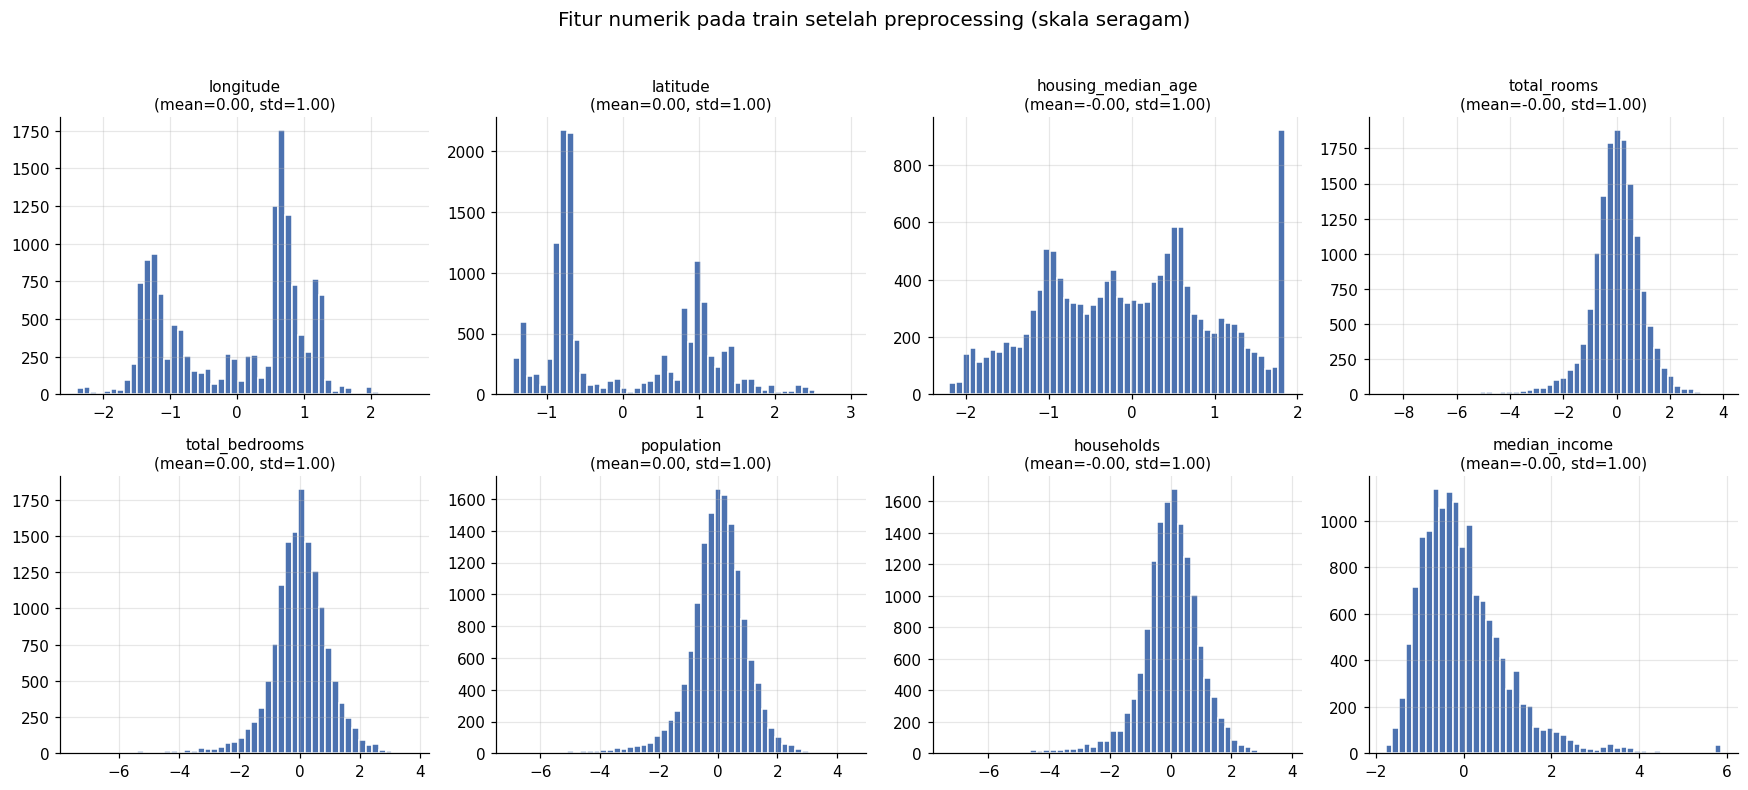

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), NUM_FEATURES):
    j = prep.columns_.index(c)
    ax.hist(X_train[:, j], bins=50, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{c}\n(mean={X_train[:, j].mean():.2f}, std={X_train[:, j].std():.2f})", fontsize=10)
fig.suptitle("Fitur numerik pada train setelah preprocessing (skala seragam)", fontsize=13, y=1.02)
plt.tight_layout()
save_fig("12_fitur_setelah_preprocessing")
plt.show()

Pada train, semua fitur memiliki mean 0 dan std 1. Pada validation dan test angkanya **tidak persis** 0 dan 1, karena keduanya
memakai statistik train, dan inilah perilaku yang benar (bila val/test punya mean tepat 0, berarti statistiknya dihitung ulang dari
data mereka, yaitu bocor). Bentuk histogram keempat fitur hitungan sekarang jauh lebih simetris dibanding sebelum `log1p`.

Satu catatan: kolom `ocean_ISLAND` hampir konstan (3 dari 14.447 baris bernilai 1), sehingga satu baris `ISLAND` di val/test
dapat bernilai sangat besar setelah standardisasi (std train hanya sekitar 0,014). Ini konsekuensi dari kategori yang sangat langka
dan diterima karena jumlahnya hanya 2 baris di luar train.

## 5. Augmentasi Data (ketentuan c)

**Keputusan: augmentasi data tidak digunakan** (jenis: tidak ada; parameter: tidak ada).

| Teknik augmentasi | Dipakai? | Alasan |
|---|---|---|
| Citra: rotasi, flip, crop, brightness | Tidak | Tidak ada citra |
| Teks: sinonim, *back-translation* | Tidak | Tidak ada teks |
| Tabular: SMOTE / oversampling | Tidak | Hanya cocok untuk label kelas; target di sini kontinu |
| Tabular: *noise injection* (tambah derau Gaussian ke fitur) | Tidak | Satu baris adalah satu blok sensus **nyata**. Menggeser `latitude`/`longitude` atau `median_income` menghasilkan blok yang tidak ada dan merusak pola geografis yang menjadi sinyal utama (EDA bagian 4) |
| Tabular: interpolasi antar-baris (mixup) | Tidak | Menggabungkan dua blok berbeda menghasilkan lokasi dan harga yang tidak bermakna |

**Mengapa memang tidak perlu:** data sudah cukup besar untuk MLP kecil (14.447 baris train untuk 13 fitur), dan risiko *overfitting*
sudah ditangani oleh teknik regularisasi, bukan penambahan data:

| Teknik | Parameter di `train.py` |
|---|---|
| Regularisasi L2 pada tiap lapisan Dense | `1e-4` |
| Dropout setelah Dense 128 dan Dense 64 | `0.2` |
| Early stopping pada validation loss | `patience = 20`, `restore_best_weights = True` |
| Penurunan learning rate bila stagnan | `ReduceLROnPlateau(patience = 8, factor = 0.5, min_lr = 1e-5)` |

Jika di tahap evaluasi terlihat *overfitting* yang jelas (jarak loss train dan validation besar), augmentasi derau Gaussian kecil
pada fitur numerik terstandardisasi (misalnya σ = 0,05 hanya pada fitur non-lokasi) dapat dicoba sebagai eksperimen terpisah, dan
dicatat sebagai perubahan terhadap pipeline ini.

## 6. Pipeline Akhir, Verifikasi, dan Penyimpanan

### 6.1 Verifikasi: apakah identik dengan backend?
Pipeline di notebook ini harus menghasilkan angka yang **sama persis** dengan `backend/preprocess.py` dan dengan `prep.json` hasil
training. Kalau tidak sama, model akan menerima input yang berbeda dari yang dilihatnya saat training.

In [ ]:
# (1) Bandingkan dengan fungsi backend pada data yang sama
b_prep = backend_prep.fit_prep(train_df)
b_X_train = backend_prep.transform(train_df, b_prep)
b_X_val = backend_prep.transform(val_df, b_prep)
b_X_test = backend_prep.transform(test_df, b_prep)

same_X = all(np.array_equal(a, b) for a, b in [(X_train, b_X_train), (X_val, b_X_val), (X_test, b_X_test)])
print("Output notebook == backend/preprocess.py (train, val, test):", same_X)

# (2) Bandingkan dengan prep.json yang dipakai model terlatih
saved_path = ROOT / "backend" / "artifacts" / "prep.json"
if saved_path.exists():
    saved = json.loads(saved_path.read_text())
    mine = prep.to_dict()
    print("columns  sama dengan prep.json:", mine["columns"] == saved["columns"])
    print("fill     sama dengan prep.json:", np.allclose(list(mine["fill"].values()), list(saved["fill"].values())))
    print("mean     sama dengan prep.json:", np.allclose(mine["mean"], saved["mean"]))
    print("std      sama dengan prep.json:", np.allclose(mine["std"], saved["std"]))
else:
    print("prep.json belum ada (jalankan backend/train.py), verifikasi (2) dilewati.")

# (3) Target
assert np.allclose(y_train, train_df[TARGET].to_numpy("float32") / TARGET_SCALE)
assert np.allclose(HousingPreprocessor.inverse_target(y_test), test_df[TARGET].to_numpy(), rtol=1e-5)
print("Skala target dan pengembaliannya ke USD: OK")

Output notebook == backend/preprocess.py (train, val, test): True
columns  sama dengan prep.json: True
fill     sama dengan prep.json: True
mean     sama dengan prep.json: True
std      sama dengan prep.json: True
Skala target dan pengembaliannya ke USD: OK


### 6.2 Uji akhir: baris baru dengan nilai kosong

Memastikan pipeline sanggup menangani input yang tidak lengkap (kasus yang tidak terwakili val/test, lihat bagian 2.2).

In [ ]:
sample = pd.DataFrame([{
    "longitude": -122.23, "latitude": 37.88, "housing_median_age": 41, "total_rooms": 880,
    "total_bedrooms": np.nan,          # sengaja kosong
    "population": 322, "households": 126, "median_income": 8.3252, "ocean_proximity": "NEAR BAY",
}])
x = prep.transform(sample)
print("Bentuk:", x.shape, "| ada NaN:", bool(np.isnan(x).any()))
display(pd.DataFrame(x, columns=prep.columns_).round(3))

Bentuk: (1, 13) | ada NaN: False


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_<1H OCEAN,ocean_INLAND,ocean_ISLAND,ocean_NEAR BAY,ocean_NEAR OCEAN
0,-1.335,1.063,0.977,-1.12,0.032,-1.697,-1.565,2.35,-0.887,-0.679,-0.014,2.819,-0.391


### 6.3 Menyimpan hasil

In [ ]:
# Array siap pakai untuk notebook pemodelan berikutnya
np.savez_compressed(
    OUT_DIR / "housing_processed.npz",
    X_train=X_train, X_val=X_val, X_test=X_test,
    y_train=y_train, y_val=y_val, y_test=y_test,
    columns=np.array(prep.columns_),
)
# Parameter preprocessing (format sama dengan prep.json)
(OUT_DIR / "preprocessor.json").write_text(json.dumps(prep.to_dict(), indent=2))

# Catatan: backend/artifacts/prep.json TIDAK ditimpa, karena itu milik model yang sudah dilatih.
for f in sorted(OUT_DIR.glob("*")):
    print(f"{f.relative_to(ROOT)}  ({f.stat().st_size / 1024:,.0f} KB)")

data/processed/housing_processed.npz  (446 KB)
data/processed/preprocessor.json  (1 KB)


## Rangkuman Preprocessing

| Ketentuan | Langkah | Alasan singkat | Hasil di data ini |
|---|---|---|---|
| a. Pembersihan | Cek duplikat, tipe, rentang, logika, label | Cegah pola ganda dan nilai mustahil | 0 duplikat, 0 nilai di luar rentang; 3 baris `households > population` dan 965 target terpotong dicatat, dipertahankan |
| e. Pembagian | Acak (seed 42), 70/15/15 | Evaluasi jujur; statistik hanya dari train | 14.447 / 3.096 / 3.097 baris; distribusi antar-subset mirip |
| e. Anti-bocor | Split dulu, fit di train, val untuk early stopping, test sekali | Cegah informasi val/test masuk ke training | 0 baris tumpang tindih; parameter disimpan |
| d. Missing value | Imputasi median dari train | MLP tidak menerima NaN; median kuat pada data miring | 207 nilai `total_bedrooms` (semuanya di train) terisi 433 |
| d. Outlier | Tidak dihapus; diredam `log1p` | Blok besar itu valid dan akan muncul saat inference | Skewness 3,5 sampai 4,3 turun ke sekitar −1 |
| d. Ketidakseimbangan | Tidak ada resampling | Regresi tidak punya kelas; distribusi antar-split mirip | `ISLAND` (5 baris) dan target terpotong dicatat sebagai keterbatasan |
| b. Normalisasi | `log1p` + one-hot + z-score (train), target ÷ 100.000 | Skala fitur seragam agar gradient descent stabil | 13 fitur, mean 0 dan std 1 pada train |
| b. Citra/teks | Tidak relevan | Data tabular | – |
| c. Augmentasi | Tidak digunakan | Baris adalah blok nyata; overfitting ditangani regularisasi | L2 `1e-4`, Dropout 0,2, early stopping |

## Kesimpulan

Pipeline preprocessing dibangun sebagai kelas `HousingPreprocessor` yang menghasilkan output **identik dengan `backend/preprocess.py`**
dan parameter yang sama dengan `backend/artifacts/prep.json`, sehingga apa yang dilihat model saat training sama dengan yang diterimanya
saat dipakai lewat API. Data dibagi lebih dulu dan semua statistik dihitung dari train, sehingga bebas kebocoran.

Batasan yang perlu dibawa ke tahap evaluasi: (1) target terpotong di \$500.001, (2) kategori `ISLAND` hanya 5 baris, (3) seluruh nilai kosong
berada di train sehingga jalur imputasi tidak diuji oleh val/test, dan (4) 3 baris dengan `households > population` tetap dipakai.

Langkah berikutnya: notebook pemodelan MLP yang memuat `data/processed/housing_processed.npz`.